# Case Study 09 — Overlapping Risk Signals in a Credit-Limit Model

**Multicollinearity · correlation matrix · VIF, tolerance and condition number · unstable coefficients and sign flips ·
individually insignificant but jointly decisive variables · prediction vs interpretation · when multicollinearity DOES
hurt prediction · perfect and structural collinearity · remedies: drop, combine, PCA, ridge**

| | |
|---|---|
| **Domain** | Credit cards: credit-limit assignment |
| **Stakeholders** | Head of Cards, Credit Risk model owner |
| **Difficulty** | Intermediate |
| **Importance** | 🟠 SHOULD GO THROUGH |
| **Builds on** | Case 05 (correlation), Case 07 (multiple regression), Case 08 (what happens when variables are added) |
| **Data** | 4,000 salaried card customers (4 quarterly cohorts) + 600 self-employed customers from a digital pilot |

> **This dataset is synthetic** and was generated to reproduce a realistic business scenario. It is not actual
> customer data. See `src/generate_data.py`.

**What you will learn**

1. How to **recognise** multicollinearity (symptoms) and **measure** it (correlation matrix, VIF, condition number).
2. **Why** it makes coefficients unstable and standard errors large, and why their **sum** can still be precise.
3. Why it usually does **not** hurt prediction, and the important case in which it **does**: when the correlation
   pattern changes in deployment.
4. How to tell harmless from harmful multicollinearity, and which remedy to use when.

## Section 1 — Business context

Card limits are set as a multiple of each customer's predicted **spending capacity** (average monthly card spend).
The spend model is refitted every quarter on about 1,000 new customers. The Head of Cards writes:

> *"Every quarter the model's coefficients look completely different. In Q2 neither income variable was even
> significant. In Q4 'salary credits' came out **negative**, so the model now says that customers with more money
> coming into their account spend less. Product wants to drop salary credits; Risk says the model is broken. Meanwhile
> we are launching cards for self-employed customers through our digital pilot. Can we use this model for them?"*

The model uses several signals of a customer's financial capacity:
- **declared income** (application form),
- **salary credits** (average monthly credits into the customer's account with us),
- **average balance**, **card limits with other banks** (bureau), number of other cards,
- obligations (EMIs + rent), credit score, age, relationship length.

## Section 2 — Business questions

1. Why do the coefficients change so much between quarters? Is the model broken?
2. In Q2 neither income variable was significant. Does income not matter?
3. In Q4 salary credits got a negative coefficient. Do customers with more credits really spend less?
4. Do the **predictions** (and so the limits) jump around too?
5. Can the model be used for the self-employed pilot?
6. How should we fix the model?

## Section 3 — Statistical translation

| # | Business question | Statistical question | Method |
|---|---|---|---|
| 1 | Why do coefficients jump? | Are predictors so correlated that their separate effects are poorly identified? | Correlation matrix, VIF, condition number, quarterly refits |
| 2 | Does income not matter? | Individual t-tests vs a **joint** F-test of the income variables | t-tests, F-test |
| 3 | Negative sign? | Is the split between two near-identical variables estimable? | SE inflation, bootstrap of the coefficient pair, simulation |
| 4 | Do predictions jump? | Stability of fitted values vs coefficients | Predictions of the quarterly models on the same customers; cross-validation |
| 5 | Use for the pilot? | Does the **correlation structure** hold in the new segment? | Correlations by segment, bias on pilot customers |
| 6 | How to fix? | Compare remedies on stability, accuracy and interpretability | Drop one, average into an index, PCA, ridge regression |

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.decomposition import PCA
from sklearn.model_selection import KFold

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "00_shared_resources").is_dir())
sys.path.insert(0, str(ROOT / "00_shared_resources"))
from utils import case_paths, save_table, fmt_money, fmt_p, rng_for_case
from plotting import set_style, save_fig, add_note, thousands_formatter, COLORS, CATEGORICAL, PRIMARY, HIGHLIGHT, INK, INK_MUTED

CASE_DIR = ROOT / "case_studies" / "09_multicollinearity_credit_limit"
PATHS = case_paths(CASE_DIR)
set_style()
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
rng = rng_for_case(909)
kfmt = thousands_formatter("₹", "k", 1e3, 0)

## Section 4 — Load the data

In [2]:
cust = pd.read_csv(PATHS["data"] / "card_customers.csv")
print(f"{cust.shape[0]:,} customers × {cust.shape[1]} columns;  duplicates: {cust['customer_id'].duplicated().sum()};  "
      f"missing: {cust.isna().sum().sum()}")
print(cust.groupby(["segment", "quarter"]).size().to_string())
display(cust.head())

for c in ["declared_income", "salary_credits", "avg_balance", "avg_monthly_spend"]:
    cust[f"log_{c}"] = np.log(cust[c])
cust["log_bureau_limits"] = np.log1p(cust["bureau_card_limits"])     # log(1 + x): 0 for customers with no other cards
cust["obligation_share"] = cust["total_obligations"] / cust["declared_income"]
ex = cust[cust["segment"] == "Salaried (existing)"].copy()
pilot = cust[cust["segment"] != "Salaried (existing)"].copy()
print(f"\nExisting salaried customers: {len(ex):,}   |   Self-employed pilot: {len(pilot):,}")

4,600 customers × 15 columns;  duplicates: 0;  missing: 0
segment                        quarter
Salaried (existing)            2025-Q1    1000
                               2025-Q2    1000
                               2025-Q3    1000
                               2025-Q4    1000
Self-employed (digital pilot)  Pilot       600


,customer_id,quarter,segment,age,months_with_bank,credit_score,declared_income,salary_credits,avg_balance,bureau_card_limits,num_other_cards,existing_emi,rent,total_obligations,avg_monthly_spend
0,CC9100000,2025-Q1,Salaried (existing),33,41,715,"68,800.0000","71,900.0000","97,100.0000",0.0000,0,"6,300.0000","12,400.0000","18,700.0000","19,630.0000"
1,CC9100001,2025-Q1,Salaried (existing),44,113,785,"54,800.0000","55,300.0000","64,300.0000",0.0000,0,0.0000,0.0000,0.0000,"13,170.0000"
2,CC9100002,2025-Q1,Salaried (existing),48,23,670,"105,400.0000","106,500.0000","89,000.0000",0.0000,0,"30,200.0000",0.0000,"30,200.0000","26,950.0000"
3,CC9100003,2025-Q1,Salaried (existing),37,52,734,"84,000.0000","79,000.0000","107,500.0000","246,000.0000",1,0.0000,"18,600.0000","18,600.0000","31,820.0000"
4,CC9100004,2025-Q1,Salaried (existing),38,20,685,"58,600.0000","58,700.0000","97,200.0000","155,000.0000",1,0.0000,0.0000,0.0000,"16,870.0000"



Existing salaried customers: 4,000   |   Self-employed pilot: 600


Money variables are right-skewed, so we model **log(spend)** on **log** income signals (coefficients are elasticities,
Case 06). Card limits with other banks are zero for customers without other cards, so we use log(1 + limits).

**Two data sets, two roles.** The 4,000 existing salaried customers are used to build and study the model. The 600
pilot customers are kept aside to answer Question 5.

## Section 5 — Descriptive statistics and the correlation matrix

,median: Salaried (existing),median: Self-employed (digital pilot)
avg_monthly_spend,"16,805.0000","17,180.0000"
declared_income,"70,700.0000","74,150.0000"
salary_credits,"70,800.0000","39,900.0000"
avg_balance,"63,600.0000","65,750.0000"
bureau_card_limits,0.0000,"51,500.0000"
num_other_cards,0.0000,1.0000
total_obligations,"10,200.0000","11,400.0000"
credit_score,731.0000,732.0000
age,35.0000,35.0000
months_with_bank,40.0000,40.0000


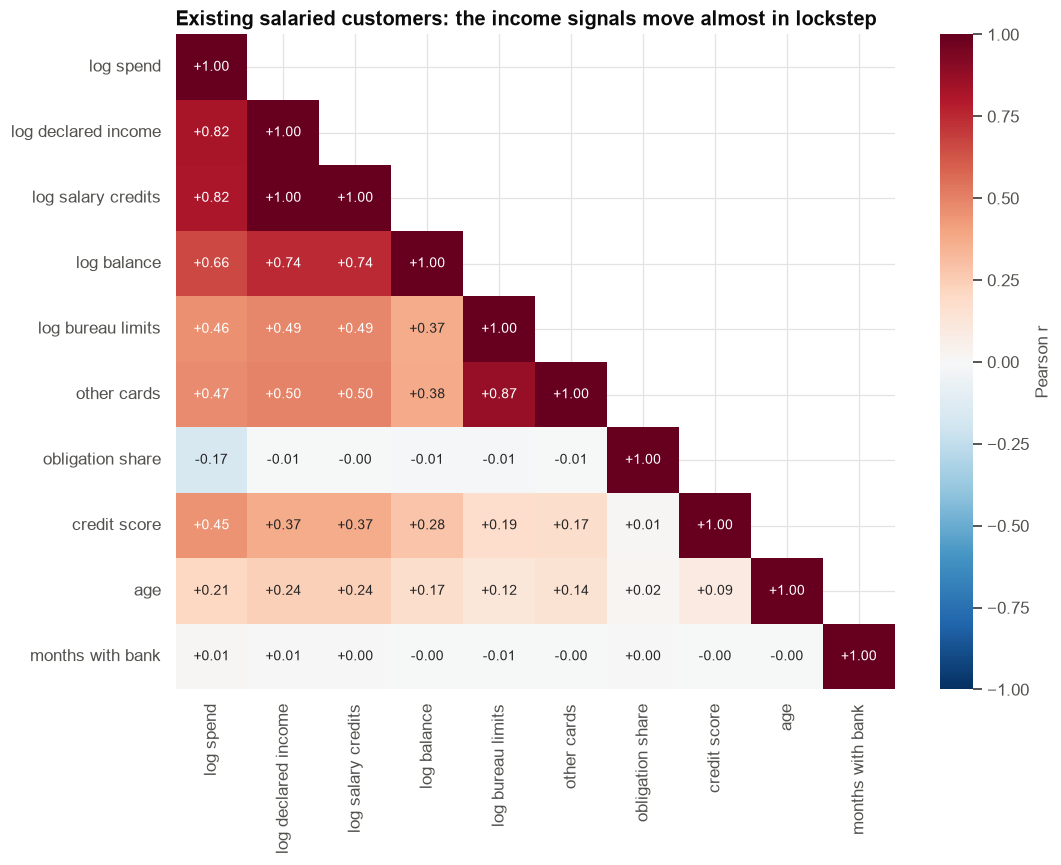

In [3]:
num = ["avg_monthly_spend", "declared_income", "salary_credits", "avg_balance", "bureau_card_limits", "num_other_cards",
       "total_obligations", "credit_score", "age", "months_with_bank"]
desc = cust.groupby("segment")[num].median().T
desc.columns = [f"median: {c}" for c in desc.columns]
save_table(desc, "medians_by_segment", PATHS["tables"])
display(desc)

corr_vars = {"log_avg_monthly_spend": "log spend", "log_declared_income": "log declared income",
             "log_salary_credits": "log salary credits", "log_avg_balance": "log balance",
             "log_bureau_limits": "log bureau limits", "num_other_cards": "other cards",
             "obligation_share": "obligation share", "credit_score": "credit score", "age": "age",
             "months_with_bank": "months with bank"}
corr = ex[list(corr_vars)].rename(columns=corr_vars).corr()
save_table(corr, "correlation_matrix_existing", PATHS["tables"])
fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt="+.2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0, ax=ax,
            cbar_kws={"label": "Pearson r"}, annot_kws={"size": 9})
ax.set_title("Existing salaried customers: the income signals move almost in lockstep", loc="left")
fig.tight_layout()
save_fig(fig, "fig01_correlation_matrix", PATHS["figures"])
plt.show()

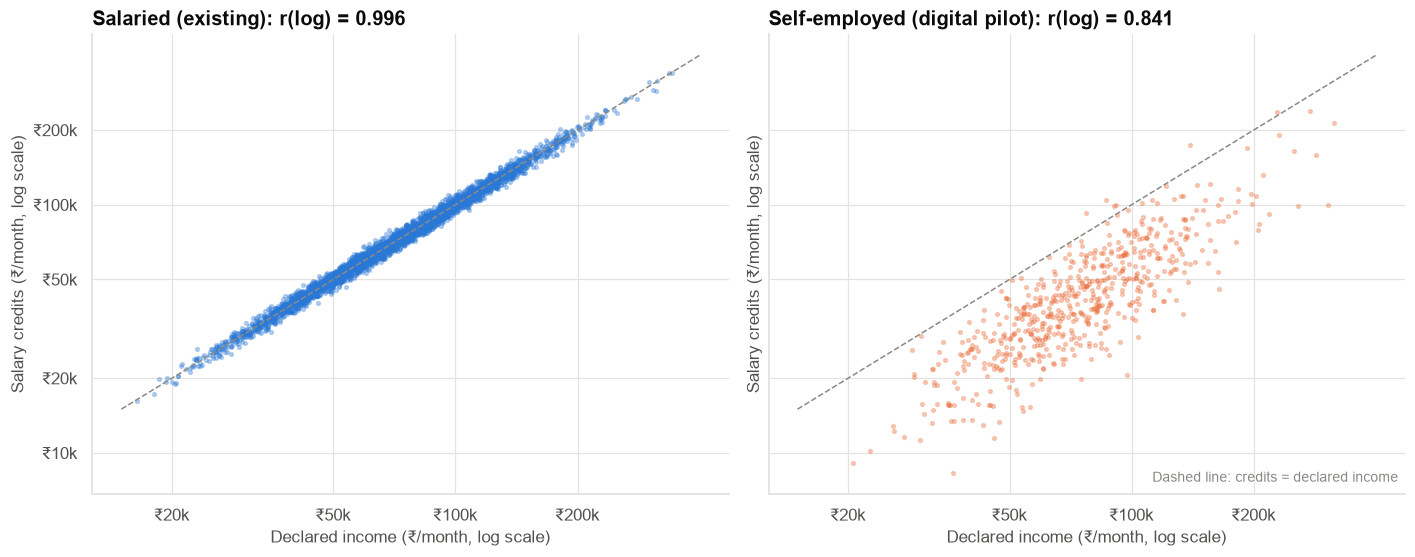

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), sharex=True, sharey=True)
for ax, (seg, sub), col in zip(axes, [("Salaried (existing)", ex), ("Self-employed (digital pilot)", pilot)], [PRIMARY, HIGHLIGHT]):
    r = np.corrcoef(sub["log_declared_income"], sub["log_salary_credits"])[0, 1]
    ax.scatter(sub["declared_income"], sub["salary_credits"], s=6, alpha=0.3, color=col)
    lim = [15_000, 400_000]
    ax.plot(lim, lim, color=INK_MUTED, ls="--", lw=1)
    ax.set_xscale("log"); ax.set_yscale("log")
    for a in (ax.xaxis, ax.yaxis):
        a.set_major_formatter(kfmt); a.set_minor_formatter(plt.NullFormatter())
    ax.set_xticks([20_000, 50_000, 100_000, 200_000]); ax.set_yticks([10_000, 20_000, 50_000, 100_000, 200_000])
    ax.set(title=f"{seg}: r(log) = {r:.3f}", xlabel="Declared income (₹/month, log scale)",
           ylabel="Salary credits (₹/month, log scale)")
add_note(axes[1], "Dashed line: credits = declared income", "lower right")
fig.tight_layout()
save_fig(fig, "fig02_two_income_signals", PATHS["figures"])
plt.show()

**Observation.** For salaried customers, declared income and salary credits are almost the same number (r ≈ 0.996 on
the log scale). Both are also strongly correlated with balances (≈ 0.74) and with spend (≈ 0.82). For self-employed
pilot customers, the two diverge: credits are often far **below** declared income (r ≈ 0.84).

**Interpretation.** For a salaried customer, the salary is paid into the account, so both columns measure the same
thing. That is **multicollinearity**: two (or more) predictors carry almost the same information. Self-employed
customers receive much of their income elsewhere (cash, other accounts), so for them the two signals mean different
things. Keep this in mind for Question 5.

## Section 6 — The symptom: quarterly refits

In [5]:
CTRL = "log_avg_balance + log_bureau_limits + num_other_cards + obligation_share + credit_score + age + months_with_bank"
F_FULL = f"log_avg_monthly_spend ~ log_declared_income + log_salary_credits + {CTRL}"

def income_summary(m):
    t_sum = m.t_test("log_declared_income + log_salary_credits = 0")
    f_joint = m.f_test("log_declared_income = 0, log_salary_credits = 0")
    return {"b declared": m.params["log_declared_income"], "SE declared": m.bse["log_declared_income"],
            "p declared": m.pvalues["log_declared_income"],
            "b credits": m.params["log_salary_credits"], "SE credits": m.bse["log_salary_credits"],
            "p credits": m.pvalues["log_salary_credits"],
            "b SUM": float(t_sum.effect[0]), "SE SUM": float(np.squeeze(t_sum.sd)),
            "joint F": float(np.squeeze(f_joint.fvalue)), "joint p": float(f_joint.pvalue), "R²": m.rsquared}

q_models = {q: smf.ols(F_FULL, s).fit() for q, s in ex.groupby("quarter")}
m_all = smf.ols(F_FULL, ex).fit()
quarterly = pd.DataFrame({**{q: income_summary(m) for q, m in q_models.items()}, "All 4 quarters": income_summary(m_all)}).T
save_table(quarterly, "quarterly_income_coefficients", PATHS["tables"])
quarterly

,b declared,SE declared,p declared,b credits,SE credits,p credits,b SUM,SE SUM,joint F,joint p,R²
2025-Q1,0.2373,0.2325,0.3077,0.6022,0.2321,0.0096,0.8394,0.0342,301.0174,0.0000,0.7392
2025-Q2,0.3428,0.2227,0.1241,0.3982,0.2232,0.0747,0.7410,0.0349,225.2314,0.0000,0.7408
2025-Q3,0.6250,0.2203,0.0047,0.1780,0.2202,0.4189,0.8031,0.0351,262.2230,0.0000,0.7364
2025-Q4,0.8607,0.2183,0.0001,-0.0359,0.2181,0.8692,0.8247,0.0349,281.0920,0.0000,0.7431
All 4 quarters,0.5166,0.1113,0.0000,0.2871,0.1113,0.0099,0.8038,0.0173,"1,074.5944",0.0000,0.7378


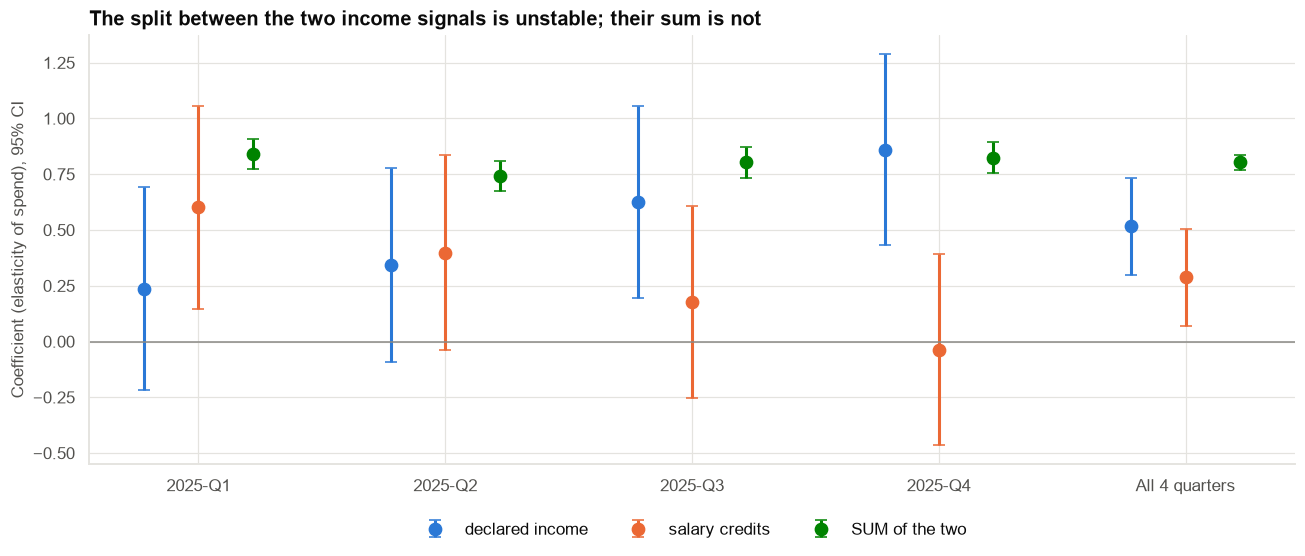

In [6]:
fig, ax = plt.subplots(figsize=(12, 5.2))
labels = list(quarterly.index)
x = np.arange(len(labels))
for off, (b, se, lab, col) in zip([-0.22, 0, 0.22], [("b declared", "SE declared", "declared income", PRIMARY),
                                                    ("b credits", "SE credits", "salary credits", HIGHLIGHT),
                                                    ("b SUM", "SE SUM", "SUM of the two", COLORS["green"])]):
    ax.errorbar(x + off, quarterly[b], yerr=1.96 * quarterly[se], fmt="o", ms=8, capsize=4, lw=2, color=col, label=lab)
ax.axhline(0, color=INK_MUTED, lw=1)
ax.set_xticks(x, labels)
ax.set(ylabel="Coefficient (elasticity of spend), 95% CI",
       title="The split between the two income signals is unstable; their sum is not")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3, frameon=False)
fig.tight_layout()
save_fig(fig, "fig03_quarterly_coefficients", PATHS["figures"])
plt.show()

**Observation.**
- The **declared-income** coefficient ranges from about 0.24 to 0.86 across quarters; **salary credits** from about
  0.60 down to **−0.04**. Their confidence intervals are very wide (about ±0.4 per quarter).
- In **Q2**, neither is significant on its own (p ≈ 0.12 and 0.07), yet the **joint F-test** of both is overwhelming
  (F in the hundreds, p < 0.001).
- The **sum** of the two coefficients is stable, about 0.8 in every quarter, with a narrow CI.

**Interpretation.** The data can tell us precisely how much spend rises with **income** (the sum, ≈ 0.8: 10% more
income → about 8% more spend). It **cannot** tell us how to split that effect between two columns that almost always
move together. Each quarter's split is mostly noise.

> **Answer to Q2.** "Neither income variable is significant" does **not** mean income doesn't matter. Individual
> t-tests ask "does this variable add anything **given the other one**?" With two near-copies, the answer for each is
> "not much", even though **together** they are the strongest predictor in the model. Always test collinear variables
> **jointly**.

> **Answer to Q3.** The negative sign in Q4 is noise, not a finding: its CI runs from about −0.46 to +0.39. "Customers
> with more salary credits spend less" would require comparing customers with the **same declared income** but
> different credits, and for salaried customers there are almost no such customers.

## Section 7 — Diagnosis: VIF, tolerance and condition number

The **variance inflation factor** of predictor j is VIF_j = 1 / (1 − R²_j), where R²_j comes from regressing X_j on
all the **other** predictors. It is exactly the factor by which the **variance** of b_j is inflated relative to
uncorrelated predictors, so standard errors are inflated by **√VIF**.

In [7]:
pred_cols = ["log_declared_income", "log_salary_credits", "log_avg_balance", "log_bureau_limits", "num_other_cards",
             "obligation_share", "credit_score", "age", "months_with_bank"]
def vif_table(df, cols):
    X = df[cols].assign(const=1.0).to_numpy()
    v = pd.Series([variance_inflation_factor(X, i) for i in range(len(cols))], index=cols)
    return pd.DataFrame({"VIF": v, "tolerance (1/VIF)": 1 / v, "R² on other predictors": 1 - 1 / v,
                         "SE inflation (√VIF)": np.sqrt(v)})
vif = vif_table(ex, pred_cols).sort_values("VIF", ascending=False)
save_table(vif, "vif_full_model", PATHS["tables"])
display(vif)

Z = StandardScaler().fit_transform(ex[pred_cols])
eig = np.linalg.eigvalsh(np.corrcoef(Z, rowvar=False))
eigval, eigvec = np.linalg.eigh(np.corrcoef(Z, rowvar=False))
print(f"Condition number of the standardised predictors: {np.sqrt(eig.max() / eig.min()):.0f}  "
      f"(rules of thumb: 10–30 moderate, > 30 strong)")
print("Smallest eigenvalue {:.4f}; the predictors that load on it:".format(eigval[0]))
print(pd.Series(eigvec[:, 0], index=pred_cols).round(3).loc[lambda s: s.abs() > 0.1].to_string())
m_decl_only = smf.ols(F_FULL.replace("log_salary_credits + ", ""), ex).fit()
print(f"SE of declared-income coefficient: with credits {m_all.bse['log_declared_income']:.4f}, "
      f"without credits {m_decl_only.bse['log_declared_income']:.4f}  → ratio {m_all.bse['log_declared_income'] / m_decl_only.bse['log_declared_income']:.1f}")

,VIF,tolerance (1/VIF),R² on other predictors,SE inflation (√VIF)
log_declared_income,115.6025,0.0087,0.9913,10.7519
log_salary_credits,115.3027,0.0087,0.9913,10.7379
num_other_cards,4.1987,0.2382,0.7618,2.0491
log_bureau_limits,4.1326,0.2420,0.7580,2.0329
log_avg_balance,2.2470,0.4450,0.5550,1.4990
credit_score,1.1654,0.8581,0.1419,1.0795
age,1.0628,0.9410,0.0590,1.0309
obligation_share,1.0047,0.9953,0.0047,1.0024
months_with_bank,1.0026,0.9974,0.0026,1.0013


Condition number of the standardised predictors: 29  (rules of thumb: 10–30 moderate, > 30 strong)
Smallest eigenvalue 0.0044; the predictors that load on it:
log_declared_income   -0.7080
log_salary_credits     0.7070
SE of declared-income coefficient: with credits 0.1113, without credits 0.0173  → ratio 6.4


**Observation.** Declared income and salary credits have VIFs above 100: each is 99% explained by the other predictors,
so their standard errors are about **11 times** larger than they would be if they were uncorrelated with everything.
Removing salary credits shrinks the SE of declared income about 6-fold (from 0.111 to 0.017). That matches the formula:
declared income still overlaps a little with balance and bureau limits (VIF ≈ 2.8 without credits), and
√(115 / 2.8) ≈ 6.4. The other predictors have VIFs below 5.

The **condition number** (≈ 29) sits at the border of "strong". It summarises the whole matrix in one number; the
**eigenvector** of the smallest eigenvalue tells you *which* variables form the near-dependency: declared income and
salary credits with opposite signs, i.e. their **difference** is almost constant.

**How to read VIF (rules of thumb, not laws):**

| VIF | Meaning | Typical action |
|---|---|---|
| 1 | Uncorrelated with other predictors | None |
| 1–5 | Moderate overlap | Usually fine |
| 5–10 | High overlap; SEs 2–3× larger | Check if you need to **interpret** this coefficient |
| > 10 | Severe; coefficient sign and size unreliable | Act **if** you interpret the coefficient, or if the correlation may change in deployment |

## Section 8 — Why it happens: two experiments

### 8.1 A simulation: increase the correlation, watch what breaks

Two predictors with the same true effect (0.4 each), 1,000 customers, 300 repetitions per correlation level. We record
how much the **coefficient** varies, and how much the **prediction** varies for two kinds of customer:
- a **typical** customer, whose two signals agree (both one SD above average);
- an **unusual** customer, whose signals disagree (one +1 SD, the other −1 SD).

,SD of coefficient b1,theory: √(1/(1−r²)) × SD at r=0,"SD of prediction, typical customer","SD of prediction, unusual customer",share of fits with b1 < 0
correlation,,,,,
0.0000,0.0160,0.0160,0.0281,0.0266,0.0000
0.5000,0.0188,0.0184,0.0245,0.0376,0.0000
0.8000,0.0235,0.0266,0.0234,0.0458,0.0000
0.9000,0.0363,0.0367,0.0227,0.0723,0.0000
0.9500,0.0493,0.0512,0.0222,0.0974,0.0000
0.9800,0.0760,0.0803,0.0213,0.1516,0.0000
0.9900,0.1119,0.1133,0.0221,0.2226,0.0000
0.9950,0.1640,0.1600,0.0230,0.3300,0.0133
0.9990,0.3431,0.3573,0.0216,0.6856,0.1300


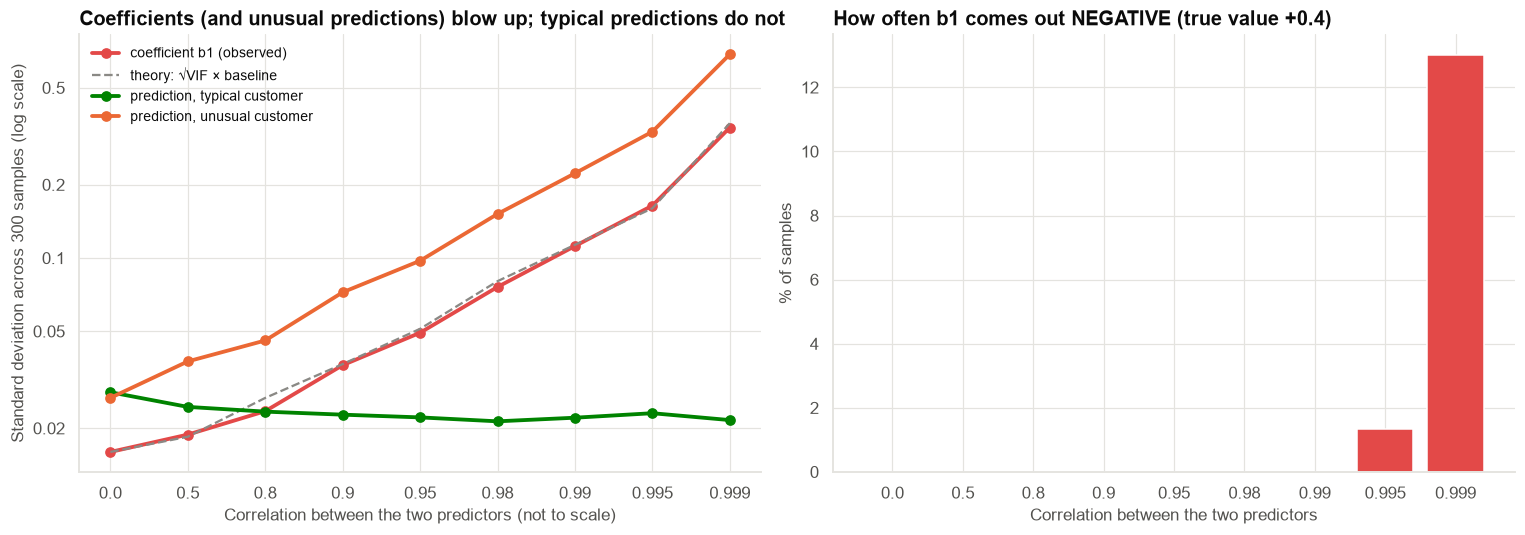

In [8]:
sim = []
for r in [0.0, 0.5, 0.8, 0.9, 0.95, 0.98, 0.99, 0.995, 0.999]:
    cov = np.array([[1, r], [r, 1]])
    b1s, p_typ, p_odd = [], [], []
    for _ in range(300):
        X = rng.multivariate_normal([0, 0], cov, size=1000)
        y = 0.4 * X[:, 0] + 0.4 * X[:, 1] + rng.normal(0, 0.5, 1000)
        A = np.column_stack([np.ones(1000), X])
        b = np.linalg.lstsq(A, y, rcond=None)[0]
        b1s.append(b[1]); p_typ.append(b[0] + b[1] + b[2]); p_odd.append(b[0] + b[1] - b[2])
    sim.append({"correlation": r, "SD of coefficient b1": np.std(b1s), "theory: √(1/(1−r²)) × SD at r=0": np.nan,
                "SD of prediction, typical customer": np.std(p_typ), "SD of prediction, unusual customer": np.std(p_odd),
                "share of fits with b1 < 0": np.mean(np.array(b1s) < 0)})
sim = pd.DataFrame(sim).set_index("correlation")
sim["theory: √(1/(1−r²)) × SD at r=0"] = sim["SD of coefficient b1"].iloc[0] / np.sqrt(1 - sim.index.to_numpy() ** 2)
save_table(sim, "collinearity_simulation", PATHS["tables"])
display(sim)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ax = axes[0]
xpos = np.arange(len(sim))
ax.plot(xpos, sim["SD of coefficient b1"], "o-", color=COLORS["red"], lw=2.5, label="coefficient b1 (observed)")
ax.plot(xpos, sim["theory: √(1/(1−r²)) × SD at r=0"], "--", color=INK_MUTED, label="theory: √VIF × baseline")
ax.plot(xpos, sim["SD of prediction, typical customer"], "o-", color=COLORS["green"], lw=2.5, label="prediction, typical customer")
ax.plot(xpos, sim["SD of prediction, unusual customer"], "o-", color=HIGHLIGHT, lw=2.5, label="prediction, unusual customer")
ax.set_yscale("log")
ax.set_yticks([0.02, 0.05, 0.1, 0.2, 0.5]); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
ax.yaxis.set_minor_formatter(plt.NullFormatter())
ax.set_xticks(xpos, [str(r) for r in sim.index])
ax.set(xlabel="Correlation between the two predictors (not to scale)", ylabel="Standard deviation across 300 samples (log scale)",
       title="Coefficients (and unusual predictions) blow up; typical predictions do not")
ax.legend(frameon=False, fontsize=9, loc="upper left")
ax = axes[1]
ax.bar([str(r) for r in sim.index], 100 * sim["share of fits with b1 < 0"], color=COLORS["red"])
ax.set(xlabel="Correlation between the two predictors", ylabel="% of samples",
       title="How often b1 comes out NEGATIVE (true value +0.4)")
fig.tight_layout()
save_fig(fig, "fig04_collinearity_simulation", PATHS["figures"])
plt.show()

**Observation.** As the correlation rises from 0 to 0.999, the coefficient's standard deviation grows about 21-fold,
as the √VIF formula predicts. At r = 0.995 a coefficient whose true value is +0.4 comes out **negative** in about 1% of
samples; at r = 0.999, in 13%. The prediction for a **typical** customer barely moves at all. The prediction for an
**unusual** customer (signals disagree) is as unstable as the coefficients.

**Interpretation.** Collinearity damages exactly the things that require separating the two variables: their
individual coefficients, and predictions for customers whose two signals point in different directions. It does not
damage what both variables agree on.

### 8.2 The same thing in our data: bootstrapping the coefficient pair

Bootstrap SD: declared 0.116, credits 0.114, SUM 0.018
Correlation between the two estimated coefficients across bootstrap samples: -0.988


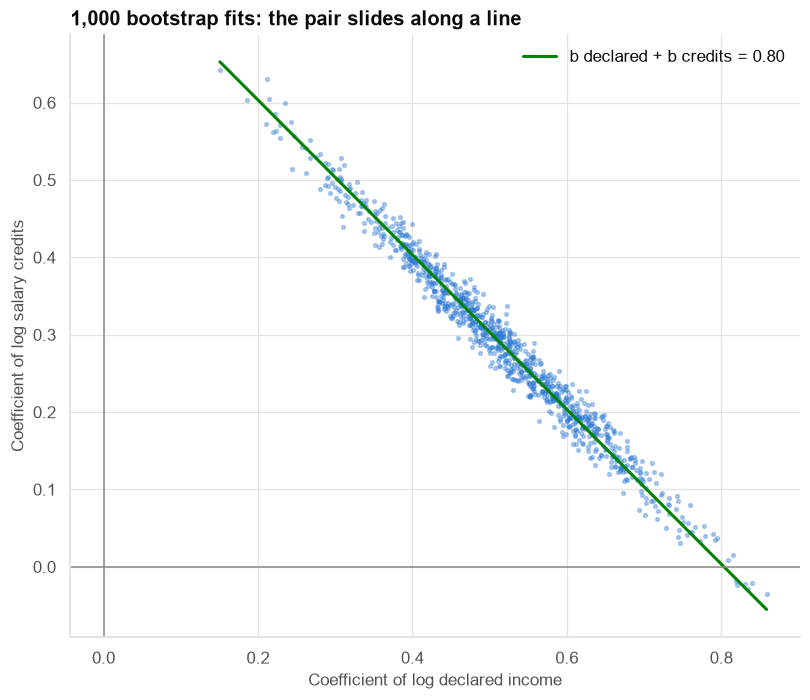

In [9]:
cols = ["log_declared_income", "log_salary_credits"] + CTRL.split(" + ")
A = np.column_stack([np.ones(len(ex)), ex[cols].to_numpy()])
yv = ex["log_avg_monthly_spend"].to_numpy()
boot = np.array([np.linalg.lstsq(A[i], yv[i], rcond=None)[0][1:3]
                 for i in (rng.integers(0, len(ex), len(ex)) for _ in range(1000))])
r_b = np.corrcoef(boot.T)[0, 1]
print(f"Bootstrap SD: declared {boot[:, 0].std():.3f}, credits {boot[:, 1].std():.3f}, SUM {boot.sum(axis=1).std():.3f}")
print(f"Correlation between the two estimated coefficients across bootstrap samples: {r_b:+.3f}")

fig, ax = plt.subplots(figsize=(7.5, 6.5))
ax.scatter(boot[:, 0], boot[:, 1], s=6, alpha=0.35, color=PRIMARY)
s = boot.sum(axis=1).mean()
xs = np.linspace(boot[:, 0].min(), boot[:, 0].max(), 10)
ax.plot(xs, s - xs, color=COLORS["green"], lw=2, label=f"b declared + b credits = {s:.2f}")
ax.axhline(0, color=INK_MUTED, lw=1); ax.axvline(0, color=INK_MUTED, lw=1)
ax.set(xlabel="Coefficient of log declared income", ylabel="Coefficient of log salary credits",
       title="1,000 bootstrap fits: the pair slides along a line")
ax.legend(frameon=False, loc="upper right")
fig.tight_layout()
save_fig(fig, "fig05_bootstrap_coefficient_pair", PATHS["figures"])
plt.show()

**Observation.** The bootstrap estimates of the two coefficients are almost perfectly **negatively** correlated
(r ≈ −0.99): when one is high the other is low, and they slide along the line "sum ≈ 0.8". The SD of each is about
0.12; the SD of the sum is about 0.02.

**Interpretation.** That is the geometry of multicollinearity. Many combinations (0.8 + 0.0, 0.4 + 0.4, 0.9 − 0.1)
fit the data almost equally well, because the two columns are nearly the same. The data pins down the **sum**, not
the **split**.

## Section 9 — Do the predictions (and limits) jump around too?

In [10]:
preds = pd.DataFrame({q: m.predict(ex) for q, m in q_models.items()})
spread = np.exp(preds.max(axis=1) - preds.min(axis=1)) - 1
print("Predictions of the four quarterly models for the SAME 4,000 customers:")
print(f"  correlation between quarterly predictions: min {preds.corr().to_numpy()[np.triu_indices(4, 1)].min():.4f}")
print(f"  largest-vs-smallest prediction per customer: median gap {spread.median():.1%}, 95th percentile {spread.quantile(0.95):.1%}")
ex["income_index"] = (ex["log_declared_income"] + ex["log_salary_credits"]) / 2
preds_idx = pd.DataFrame({q: smf.ols(f"log_avg_monthly_spend ~ income_index + {CTRL}", s.assign(
    income_index=(s["log_declared_income"] + s["log_salary_credits"]) / 2)).fit().predict(ex) for q, s in ex.groupby("quarter")})
spread_idx = np.exp(preds_idx.max(axis=1) - preds_idx.min(axis=1)) - 1
print(f"  same comparison for a model with ONE income index (no collinearity): median gap {spread_idx.median():.1%}, "
      f"95th percentile {spread_idx.quantile(0.95):.1%}")

features_full = ["log_declared_income", "log_salary_credits"] + CTRL.split(" + ")
specs = {
    "Full (both income signals)": F_FULL,
    "Declared income only": F_FULL.replace("log_salary_credits + ", ""),
    "Salary credits only": F_FULL.replace("log_declared_income + ", ""),
    "Income index (average of the two logs)": f"log_avg_monthly_spend ~ income_index + {CTRL}",
    "Neither income signal": f"log_avg_monthly_spend ~ {CTRL}",
}
ex["income_index"] = (ex["log_declared_income"] + ex["log_salary_credits"]) / 2
pilot["income_index"] = (pilot["log_declared_income"] + pilot["log_salary_credits"]) / 2
kf = KFold(10, shuffle=True, random_state=9)
cv = {k: [] for k in list(specs) + ["Ridge (all predictors, CV-tuned)"]}
for tr, te in kf.split(ex):
    a, b_ = ex.iloc[tr], ex.iloc[te]
    for k, f in specs.items():
        cv[k].append(np.sqrt(((b_["log_avg_monthly_spend"] - smf.ols(f, a).fit().predict(b_)) ** 2).mean()))
    rid = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 4, 40))).fit(a[features_full], a["log_avg_monthly_spend"])
    cv["Ridge (all predictors, CV-tuned)"].append(np.sqrt(((b_["log_avg_monthly_spend"] - rid.predict(b_[features_full])) ** 2).mean()))
cv_tbl = pd.DataFrame({"CV RMSE (log)": {k: np.mean(v) for k, v in cv.items()},
                       "fold SD": {k: np.std(v, ddof=1) for k, v in cv.items()}})
save_table(cv_tbl, "cv_prediction_accuracy", PATHS["tables"])
cv_tbl

Predictions of the four quarterly models for the SAME 4,000 customers:
  correlation between quarterly predictions: min 0.9948
  largest-vs-smallest prediction per customer: median gap 6.2%, 95th percentile 12.7%


  same comparison for a model with ONE income index (no collinearity): median gap 5.7%, 95th percentile 11.7%


,CV RMSE (log),fold SD
Full (both income signals),0.2975,0.0091
Declared income only,0.2977,0.0093
Salary credits only,0.2982,0.0086
Income index (average of the two logs),0.2975,0.0090
Neither income signal,0.3689,0.0106
"Ridge (all predictors, CV-tuned)",0.2975,0.0090


**Observation.** The four quarterly models disagree wildly about coefficients, yet their predictions for the same
4,000 salaried customers correlate above 0.99. For the median customer, the highest and lowest of the four quarterly
predictions differ by about 6%. A model **without** collinearity (one income index) refitted on the same four quarters
shows almost the same gap, so this is ordinary refitting noise from 1,000 customers per quarter, not a collinearity
problem. In cross-validation, the full model, either single signal, the index and ridge all predict equally well
(RMSE ≈ 0.298). Removing **both** income signals is much worse (0.369).

**Interpretation.**
> **For salaried customers, multicollinearity does not hurt prediction.** The model always gets the **sum** right,
> and for these customers the two signals always agree. Limits did not jump around; only the coefficients did.

**Answer to Q1 and Q4.** The model is not "broken" for its current population: its predictions are stable and accurate.
What is broken is **reading its coefficients** as separate effects.

## Section 10 — When multicollinearity DOES hurt prediction: the self-employed pilot

The rule "multicollinearity doesn't affect prediction" has a condition: **the new customers must have the same
correlation pattern as the training data.** Self-employed customers do not (Section 5).

In [11]:
def pilot_bias(pred_log, y=pilot["log_avg_monthly_spend"]):
    e = y - pred_log
    lo, hi = stats.t.interval(0.95, len(e) - 1, loc=e.mean(), scale=e.std(ddof=1) / np.sqrt(len(e)))
    return {"mean error (actual vs predicted, %)": 100 * (np.exp(e.mean()) - 1),
            "ci_low %": 100 * (np.exp(lo) - 1), "ci_high %": 100 * (np.exp(hi) - 1),
            "RMSE (log)": np.sqrt((e ** 2).mean())}

pb = {}
for k, f in specs.items():
    pb[k] = pilot_bias(smf.ols(f, ex).fit().predict(pilot))
rid_all = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 4, 40))).fit(ex[features_full], ex["log_avg_monthly_spend"])
pb["Ridge (all predictors, CV-tuned)"] = pilot_bias(rid_all.predict(pilot[features_full]))
for q, m in q_models.items():
    pb[f"Full model fitted on {q} only"] = pilot_bias(m.predict(pilot))
pb = pd.DataFrame(pb).T
save_table(pb, "pilot_prediction_bias", PATHS["tables"])
pb

,"mean error (actual vs predicted, %)",ci_low %,ci_high %,RMSE (log)
Full (both income signals),17.9239,15.0223,20.8987,0.3515
Declared income only,-0.6667,-3.0462,1.7712,0.3022
Salary credits only,59.9938,55.2818,64.8489,0.5997
Income index (average of the two logs),26.2939,23.0952,29.5758,0.3959
Neither income signal,0.7312,-2.2347,3.7871,0.3725
"Ridge (all predictors, CV-tuned)",23.1915,20.1069,26.3554,0.3786
Full model fitted on 2025-Q1 only,42.6237,38.7351,46.6212,0.4947
Full model fitted on 2025-Q2 only,27.1342,23.9079,30.4445,0.4003
Full model fitted on 2025-Q3 only,9.0942,6.4564,11.7972,0.3172
Full model fitted on 2025-Q4 only,-2.7414,-5.0750,-0.3504,0.3039


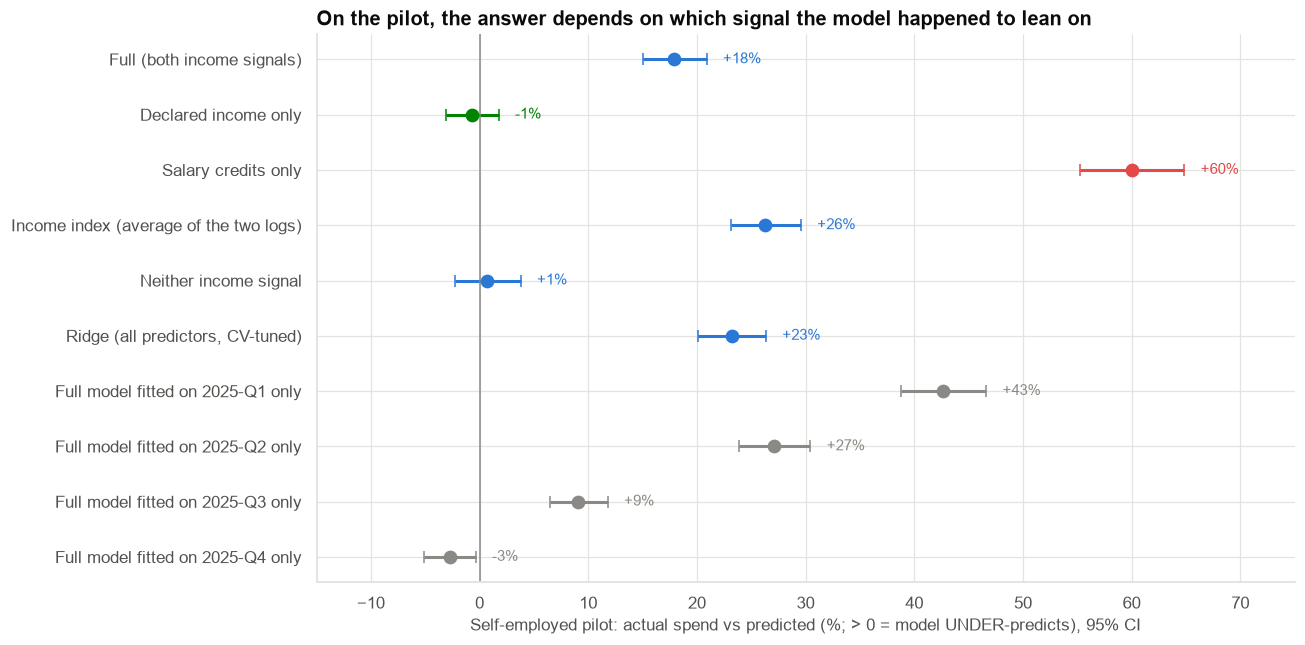

In [12]:
fig, ax = plt.subplots(figsize=(12, 6))
order = list(pb.index)[::-1]
for i, k in enumerate(order):
    r = pb.loc[k]
    col = COLORS["green"] if k == "Declared income only" else (COLORS["red"] if "credits only" in k else
                                                                 (INK_MUTED if "fitted on" in k else PRIMARY))
    est = r["mean error (actual vs predicted, %)"]
    ax.errorbar(est, i, xerr=[[est - r["ci_low %"]], [r["ci_high %"] - est]], fmt="o", color=col, ms=8, capsize=4, lw=2)
    ax.text(r["ci_high %"] + 1.5, i, f"{est:+.0f}%", va="center", fontsize=10, color=col)
ax.axvline(0, color=INK_MUTED, lw=1)
ax.set_yticks(range(len(order)), order)
ax.set(xlabel="Self-employed pilot: actual spend vs predicted (%; > 0 = model UNDER-predicts), 95% CI",
       title="On the pilot, the answer depends on which signal the model happened to lean on", xlim=(-15, 75))
fig.tight_layout()
save_fig(fig, "fig06_pilot_bias", PATHS["figures"])
plt.show()

**Observation.** On self-employed pilot customers (errors shown as "actual spend vs prediction"):
- with the **full model**, actual spend is about **18% above** the prediction;
- the **same model refitted on different quarters** gives anything from −3% to +43%, depending on how that quarter
  happened to split the weight between the two signals;
- the **credits-only** model: actual spend is about 60% above prediction;
- the **index** and **ridge** models, which give both signals similar weight: about 23–26% above;
- the **declared-income-only** model, and even the model with **no** income signal (it relies on balance and other
  cards), are about right on average, but the latter is much less precise (RMSE 0.37 vs 0.30).

**Interpretation.** For self-employed customers, salary credits capture only about half of their income. Any model that
puts weight on credits under-estimates their capacity, and the arbitrary split from the collinear fit decides **how
much**. The coefficients' instability, harmless for salaried customers, turns directly into prediction error once the
two signals stop agreeing. The simulation in Section 8.1 showed the same thing: "unusual customers" get unstable
predictions.

**Caveat.** That declared income works for the pilot is partly luck: in our pilot, declared income is honest. In real
life, self-reported income in a digital journey can be inflated. The robust conclusion is not "use declared income"
but **"a model trained on salaried customers cannot be trusted for the self-employed, and must be checked and
recalibrated on pilot data."**

> **Answer to Q5.** No, not as it is. Actual spend 18% above prediction means predicted capacity, and so limits, are
> about **15% too low** for pilot customers (1 / 1.18 ≈ 0.85). Recalibrate on pilot data, with income signals that mean the same thing for this segment.

## Section 11 — Perfect and structural multicollinearity

### 11.1 Perfect collinearity: a redundant column

The feature store contains `existing_emi`, `rent` **and** `total_obligations` (= EMI + rent, exactly).

In [13]:
Xp = ex[["existing_emi", "rent", "total_obligations"]].assign(const=1.0)
print(f"Columns: {Xp.shape[1]}, matrix rank: {np.linalg.matrix_rank(Xp.to_numpy())}  → one column is an exact combination of others")
m_perf = smf.ols("log_avg_monthly_spend ~ I(existing_emi/1000) + I(rent/1000) + I(total_obligations/1000)", ex).fit()
print(m_perf.params.round(4).to_string())
print(f"Condition number reported by statsmodels: {m_perf.condition_number:.1e}")
m_two = smf.ols("log_avg_monthly_spend ~ I(existing_emi/1000) + I(rent/1000)", ex).fit()
print(f"\nR² with the redundant column: {m_perf.rsquared:.4f};  without it: {m_two.rsquared:.4f}")
print(m_two.params.round(4).to_string())

Columns: 4, matrix rank: 3  → one column is an exact combination of others
Intercept                                   9.6019
I(existing_emi / 1000)        -34,114,448,951.3718
I(rent / 1000)                -34,114,448,951.3606
I(total_obligations / 1000)    34,114,448,951.3772
Condition number reported by statsmodels: 4.7e+14

R² with the redundant column: 0.0549;  without it: 0.0574
Intercept                9.6048
I(existing_emi / 1000)   0.0044
I(rent / 1000)           0.0145


**Observation.** The design matrix has 4 columns but rank 3. statsmodels does **not** stop with an error. It returns
coefficients of about ±34 billion that cancel each other out, a condition number of about 10¹⁴, and, because of
floating-point error, even a slightly different R². Dropping the redundant column gives finite, sensible coefficients
(about +0.4% and +1.5% spend per ₹1,000 of EMI and rent; positive because in this two-variable demo, without income,
obligations partly stand in for income, as in Case 07).

**Rule.** Perfect collinearity is a **data-design** error, not a statistical finding. Typical causes: a total plus all
its parts; a dummy for **every** category plus an intercept (the "dummy-variable trap"); the same variable in two
units (₹ and ₹ lakh); shares that always sum to 100%. Fix it by removing the redundant column. Check the **rank** of
the design matrix (or a huge condition number) in every pipeline.

### 11.2 Structural multicollinearity: polynomial terms

In [14]:
ex["inc_c"] = ex["log_declared_income"] - ex["log_declared_income"].mean()
m_raw = smf.ols("log_avg_monthly_spend ~ log_declared_income + I(log_declared_income**2)", ex).fit()
m_cen = smf.ols("log_avg_monthly_spend ~ inc_c + I(inc_c**2)", ex).fit()
v_raw = vif_table(ex.assign(sq=ex["log_declared_income"] ** 2), ["log_declared_income", "sq"])["VIF"]
v_cen = vif_table(ex.assign(sq=ex["inc_c"] ** 2), ["inc_c", "sq"])["VIF"]
struct = pd.DataFrame({"VIF (raw log income and its square)": v_raw.to_numpy(), "VIF (centred first)": v_cen.to_numpy()},
                      index=["linear term", "squared term"])
save_table(struct, "structural_collinearity", PATHS["tables"])
display(struct)
print(f"Max difference in fitted values between the two versions: {np.abs(m_raw.fittedvalues - m_cen.fittedvalues).max():.2e}")
print(f"p-value of the squared term: raw {m_raw.pvalues.iloc[2]:.4f}, centred {m_cen.pvalues.iloc[2]:.4f}  (identical)")

,VIF (raw log income and its square),VIF (centred first)
linear term,"1,268.0120",1.0014
squared term,"1,268.0120",1.0014


Max difference in fitted values between the two versions: 3.39e-13
p-value of the squared term: raw 0.7211, centred 0.7211  (identical)


**Observation.** log income and its square have VIFs above 1,000. After **centring** (subtracting the mean before
squaring), the VIFs fall to about 1, while fitted values and the test of the squared term are **identical**.

**Interpretation.** This is **structural** multicollinearity: we created it by building one term from another. It is
harmless (the model is the same) and centring removes it from the diagnostics. The same applies to **interaction
terms** (Case 07 centred income for this reason). High VIFs on polynomial or interaction terms, or on the dummies of a
categorical variable with a small reference group, are **not** a reason to drop anything.

## Section 12 — Remedies compared

In [15]:
def quarter_stability(formula, terms):
    vals = pd.DataFrame({q: smf.ols(formula, s.assign(income_index=(s["log_declared_income"] + s["log_salary_credits"]) / 2)).fit().params[terms]
                         for q, s in ex.groupby("quarter")}).T
    return vals.std(ddof=1).max(), vals.min().min(), vals.max().max()

# PCA on the two standardised income signals: the first component is (almost) their average.
pca = make_pipeline(StandardScaler(), PCA(n_components=2)).fit(ex[["log_declared_income", "log_salary_credits"]])
print(f"PCA: first component explains {pca[-1].explained_variance_ratio_[0]:.1%} of the two signals' variance; "
      f"loadings {np.round(pca[-1].components_[0], 3)}")

rows = []
for name, spec, terms in [("Keep both (as is)", "Full (both income signals)", ["log_declared_income", "log_salary_credits"]),
                          ("Drop salary credits", "Declared income only", ["log_declared_income"]),
                          ("Drop declared income", "Salary credits only", ["log_salary_credits"]),
                          ("Combine into an index", "Income index (average of the two logs)", ["income_index"])]:
    sd, lo, hi = quarter_stability(specs[spec], terms)
    vmax = vif_table(ex, terms + CTRL.split(" + "))["VIF"].max()
    rows.append({"remedy": name, "max VIF": vmax, "income coef. range across quarters": f"{lo:+.2f} to {hi:+.2f}",
                 "quarter-to-quarter SD": sd, "CV RMSE": cv_tbl.loc[spec, "CV RMSE (log)"],
                 "pilot error %": pb.loc[spec, "mean error (actual vs predicted, %)"]})

ridge_coefs = {}
for q, s in ex.groupby("quarter"):
    rq = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 4, 40))).fit(s[features_full], s["log_avg_monthly_spend"])
    ridge_coefs[q] = rq[-1].coef_[:2] / rq[0].scale_[:2]    # back to the original (elasticity) scale
ridge_coefs = pd.DataFrame(ridge_coefs, index=["declared", "credits"]).T
rows.append({"remedy": "Ridge regression", "max VIF": np.nan,
             "income coef. range across quarters": f"{ridge_coefs.min().min():+.2f} to {ridge_coefs.max().max():+.2f}",
             "quarter-to-quarter SD": ridge_coefs.std(ddof=1).max(), "CV RMSE": cv_tbl.loc["Ridge (all predictors, CV-tuned)", "CV RMSE (log)"],
             "pilot error %": pb.loc["Ridge (all predictors, CV-tuned)", "mean error (actual vs predicted, %)"]})
remedies = pd.DataFrame(rows).set_index("remedy")
save_table(remedies, "remedies_comparison", PATHS["tables"])
display(remedies)
display(ridge_coefs.rename_axis("ridge coefficients by quarter"))

PCA: first component explains 99.8% of the two signals' variance; loadings [0.707 0.707]


,max VIF,income coef. range across quarters,quarter-to-quarter SD,CV RMSE,pilot error %
remedy,,,,,
Keep both (as is),115.6025,-0.04 to +0.86,0.2819,0.2975,17.9239
Drop salary credits,4.1980,+0.74 to +0.83,0.0446,0.2977,-0.6667
Drop declared income,4.1985,+0.74 to +0.84,0.0422,0.2982,59.9938
Combine into an index,4.1986,+0.74 to +0.84,0.0434,0.2975,26.2939
Ridge regression,NaN,+0.07 to +0.75,0.1822,0.2975,23.1915


,declared,credits
ridge coefficients by quarter,,
2025-Q1,0.3838,0.4356
2025-Q2,0.3600,0.3686
2025-Q3,0.4299,0.3567
2025-Q4,0.7510,0.0724


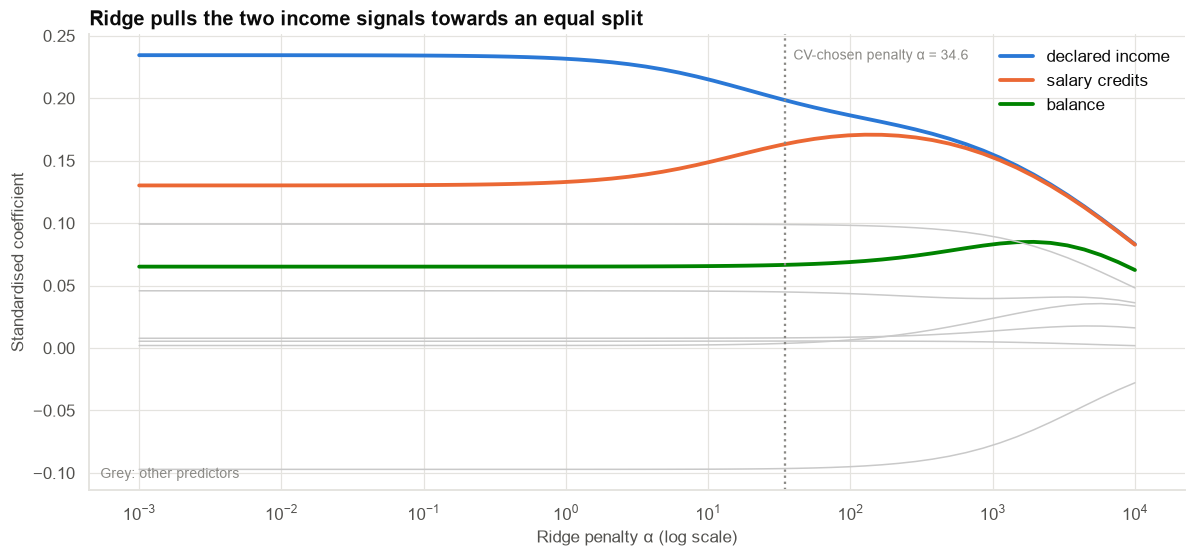

In [16]:
alphas = np.logspace(-3, 4, 60)
Zs = StandardScaler().fit(ex[features_full])
Xz = Zs.transform(ex[features_full]); yc = ex["log_avg_monthly_spend"] - ex["log_avg_monthly_spend"].mean()
path = np.array([np.linalg.solve(Xz.T @ Xz + a * np.eye(Xz.shape[1]), Xz.T @ yc) for a in alphas])
fig, ax = plt.subplots(figsize=(11, 5.2))
names = {"log_declared_income": ("declared income", PRIMARY), "log_salary_credits": ("salary credits", HIGHLIGHT),
         "log_avg_balance": ("balance", COLORS["green"])}
for j, c in enumerate(features_full):
    lab, col = names.get(c, (None, "#c9c9c9"))
    ax.plot(alphas, path[:, j], color=col, lw=2.5 if lab else 1, label=lab)
ax.axvline(rid_all[-1].alpha_, color=INK_MUTED, ls=":", lw=1.5)
ax.text(rid_all[-1].alpha_ * 1.15, ax.get_ylim()[1] * 0.92, f"CV-chosen penalty α = {rid_all[-1].alpha_:.1f}", fontsize=9, color=INK_MUTED)
ax.set_xscale("log")
ax.set(xlabel="Ridge penalty α (log scale)", ylabel="Standardised coefficient",
       title="Ridge pulls the two income signals towards an equal split")
ax.legend(frameon=False, loc="upper right")
add_note(ax, "Grey: other predictors", "lower left")
fig.tight_layout()
save_fig(fig, "fig07_ridge_path", PATHS["figures"])
plt.show()

**Observation.**
- **Keeping both**: unstable coefficients (SD across quarters ≈ 0.3) and the pilot problem.
- **Dropping one**: VIFs fall below 5, the remaining income coefficient is stable across quarters (about 0.8), and CV
  accuracy is unchanged. *Which* one to drop matters for the pilot.
- **Index** (average of the two logs; PCA's first component is almost exactly this, explaining > 99% of the variance):
  stable, interpretable, no loss of accuracy.
- **Ridge with a cross-validated penalty**: predicts as well as the others, but the coefficients are **still
  unstable** (Q4: 0.75 vs 0.07). Cross-validation chooses the penalty that predicts best, and prediction does not need
  much shrinkage here, so the penalty is small. A larger penalty would pull the two signals to an equal split and
  stabilise them, at the cost of biasing every coefficient towards zero. Ridge is a **prediction** tool; it does not
  rescue interpretation.

**How to choose a remedy:**

| Situation | Best remedy |
|---|---|
| Two columns measure the same thing; one is clearly better quality or more available | **Drop** the weaker one (domain choice) |
| Several noisy measures of one concept, all useful | **Combine** into an index (average of standardised values, or PCA) |
| Many correlated predictors, goal is prediction only | **Ridge** (or elastic net); report predictions, not coefficients (with a CV-tuned penalty, coefficients may still be unstable) |
| Collinearity from polynomials or interactions | **Centre** the variables; nothing else needed |
| Exact (perfect) collinearity | **Remove** the redundant column |
| You need the separate effect of each variable | Collect data where they **vary independently** (e.g. include segments where they disagree), or run an experiment. No statistical trick creates this information. |

## Section 13 — Decision framework: does this multicollinearity matter?

| Question | If YES | If NO |
|---|---|---|
| Do you need to **interpret** the individual coefficients of the collinear variables (drivers, policy, regulators)? | Act: drop / combine | Probably harmless |
| Are the collinear variables only **controls** you don't interpret? | Harmless: leave them | – |
| Is the goal **prediction** within the same population? | Usually harmless; check CV | – |
| Could the **correlation pattern change** where the model is used (new segment, new channel, policy change, data source change)? | **Harmful**: simplify or combine, and monitor | Harmless for prediction |
| Are the high VIFs only on **polynomial / interaction / dummy** terms? | Harmless: centre or ignore | – |
| Are individual t-tests insignificant but the joint F-test significant? | Classic collinearity: test and report the **group** | – |
| Is the coefficient sign "wrong" and the CI wide and crossing zero? | Don't interpret it; check VIF before telling any story | – |

## Section 14 — Final model

,coef,ci_low,ci_high,p_value
Intercept,-1.9059,-2.1722,-1.6397,0.0000
income_index,0.8037,0.7696,0.8378,0.0000
log_avg_balance,0.1076,0.0846,0.1307,0.0000
log_bureau_limits,0.0003,-0.0027,0.0033,0.8315
num_other_cards,0.0567,0.0341,0.0794,0.0000
obligation_share,-0.6149,-0.6744,-0.5554,0.0000
credit_score,0.0021,0.0018,0.0023,0.0000
age,0.0010,-0.0002,0.0022,0.1154
months_with_bank,0.0002,-0.0001,0.0004,0.2272


,VIF,tolerance (1/VIF),R² on other predictors,SE inflation (√VIF)
income_index,2.7900,0.3600,0.6400,1.6700
log_avg_balance,2.2500,0.4500,0.5500,1.5000
log_bureau_limits,4.1300,0.2400,0.7600,2.0300
num_other_cards,4.2000,0.2400,0.7600,2.0500
obligation_share,1.0000,1.0000,0.0000,1.0000
credit_score,1.1700,0.8600,0.1400,1.0800
age,1.0600,0.9400,0.0600,1.0300
months_with_bank,1.0000,1.0000,0.0000,1.0000


R² = 0.738


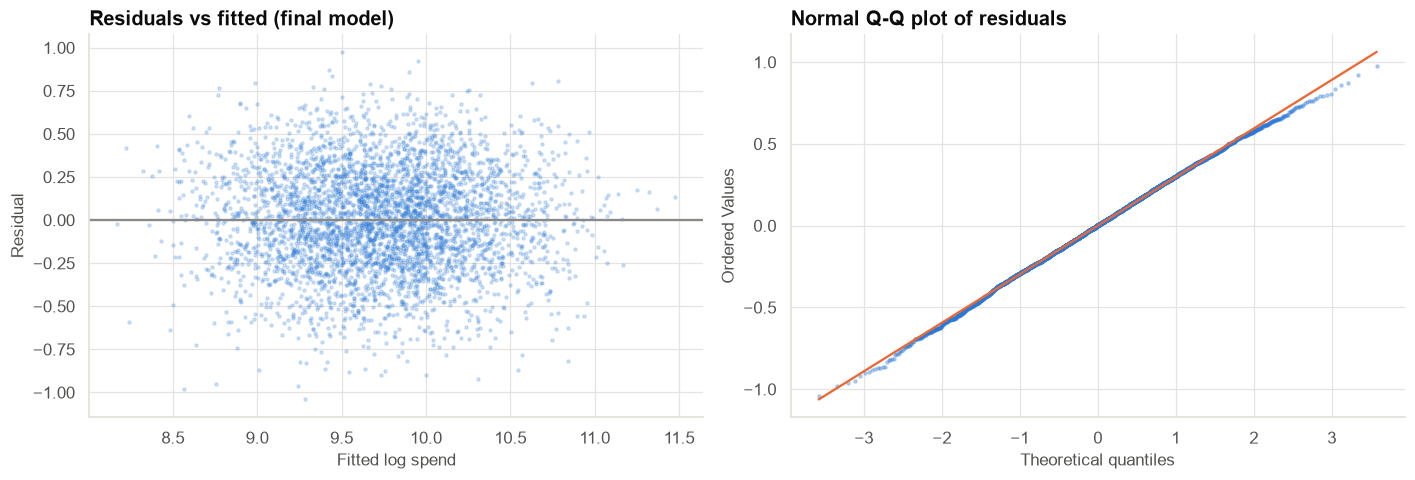

In [17]:
F_FINAL = f"log_avg_monthly_spend ~ income_index + {CTRL}"
m_final = smf.ols(F_FINAL, ex).fit(cov_type="HC3")
ci = m_final.conf_int()
final = pd.DataFrame({"coef": m_final.params, "ci_low": ci[0], "ci_high": ci[1], "p_value": m_final.pvalues})
save_table(final, "final_model_coefficients", PATHS["tables"])
display(final)
display(vif_table(ex, ["income_index"] + CTRL.split(" + ")).round(2))
print(f"R² = {m_final.rsquared:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(m_final.fittedvalues, m_final.resid, s=4, alpha=0.2, color=PRIMARY)
axes[0].axhline(0, color=INK_MUTED)
axes[0].set(xlabel="Fitted log spend", ylabel="Residual", title="Residuals vs fitted (final model)")
stats.probplot(m_final.resid, dist="norm", plot=axes[1])
axes[1].get_lines()[0].set(markersize=2, alpha=0.3, color=PRIMARY)
axes[1].get_lines()[1].set(color=HIGHLIGHT)
axes[1].set_title("Normal Q-Q plot of residuals")
fig.tight_layout()
save_fig(fig, "fig08_final_model_diagnostics", PATHS["figures"])
plt.show()

**Observation.** In the final model all VIFs are below 5. The income index has an elasticity of about 0.8 (10% more
income → about 8% more spend), with a narrow CI. Balance, the number of other cards and obligations behave as expected.
Residuals look well-behaved. (The model uses robust HC3 standard errors as a precaution; Case 10.)

## Section 15 — Results

In [18]:
summary = pd.DataFrame({
    "Finding": ["Correlation of the two income signals (salaried)", "VIF of each income signal (full model)",
                "Income coefficients across quarters", "Sum of the two (income elasticity)",
                "Q2: individual p-values / joint test", "Quarterly models' predictions (same customers)",
                "Pilot: full model error", "Pilot: error range across quarterly fits", "Final model: max VIF"],
    "Value": [f"r = {np.corrcoef(ex['log_declared_income'], ex['log_salary_credits'])[0, 1]:.3f}",
              f"{vif.loc['log_declared_income', 'VIF']:.0f} and {vif.loc['log_salary_credits', 'VIF']:.0f}",
              f"declared {quarterly['b declared'].iloc[:4].min():+.2f} to {quarterly['b declared'].iloc[:4].max():+.2f}; "
              f"credits {quarterly['b credits'].iloc[:4].min():+.2f} to {quarterly['b credits'].iloc[:4].max():+.2f}",
              f"{quarterly['b SUM'].iloc[:4].min():.2f} to {quarterly['b SUM'].iloc[:4].max():.2f} (SE ≈ {quarterly['SE SUM'].iloc[:4].mean():.3f})",
              f"p = {quarterly.loc['2025-Q2', 'p declared']:.2f} and {quarterly.loc['2025-Q2', 'p credits']:.2f}; "
              f"joint F = {quarterly.loc['2025-Q2', 'joint F']:.0f}, p < 0.001",
              f"median gap {spread.median():.1%}",
              f"{pb.loc['Full (both income signals)', 'mean error (actual vs predicted, %)']:+.0f}% (under-prediction)",
              f"{pb.filter(like='fitted on', axis=0)['mean error (actual vs predicted, %)'].min():+.0f}% to "
              f"{pb.filter(like='fitted on', axis=0)['mean error (actual vs predicted, %)'].max():+.0f}%",
              f"{vif_table(ex, ['income_index'] + CTRL.split(' + '))['VIF'].max():.1f}"]}).set_index("Finding")
save_table(summary, "results_summary", PATHS["tables"])
summary

,Value
Finding,
Correlation of the two income signals (salaried),r = 0.996
VIF of each income signal (full model),116 and 115
Income coefficients across quarters,declared +0.24 to +0.86; credits -0.04 to +0.60
Sum of the two (income elasticity),0.74 to 0.84 (SE ≈ 0.035)
Q2: individual p-values / joint test,"p = 0.12 and 0.07; joint F = 225, p < 0.001"
Quarterly models' predictions (same customers),median gap 6.2%
Pilot: full model error,+18% (under-prediction)
Pilot: error range across quarterly fits,-3% to +43%
Final model: max VIF,4.2


## Section 16 — Interpretation

- **The model is not broken; its coefficients are unidentified.** Declared income and salary credits are near-copies
  for salaried customers. The data determines their combined effect (elasticity ≈ 0.8) precisely, and their split not
  at all.
- **Insignificant individually ≠ unimportant.** In Q2 both were individually insignificant while jointly the strongest
  signal in the model. This is **scenario D** of the README: two individually useful variables that create
  multicollinearity together.
- **Wrong signs are noise.** The Q4 negative coefficient had a CI spanning about −0.46 to +0.39.
- **Predictions were stable** for salaried customers, so limits were not jumping around.
- **Predictions are NOT stable where the signals disagree**: on self-employed customers, actual spend is about 18%
  above the full model's prediction, and anywhere from −3% to +43% depending on the quarter it was fitted on.

## Section 17 — What can we say?

| ✅ We can say | ❌ We cannot say |
|---|---|
| "10% more income goes with about 8% more card spend, holding the other factors fixed." | "Salary credits have a negative effect on spend." |
| "Declared income and salary credits carry the same information for salaried customers." | "Declared income matters more than salary credits" (or vice versa), from these data. |
| "The current model predicts spend well for salaried customers." | "The current model predicts well for self-employed customers." |
| "Income signals are jointly highly significant." | "Income is not significant in Q2." |

## Section 18 — Business interpretation

- Limits for salaried customers have been set on stable predictions. **No customer-facing problem so far.**
- The dashboards and model documentation that **interpret** the coefficients ("credits have a negative effect") are
  misleading, and could mislead regulators or product decisions.
- Rolling the model out to self-employed customers would give them limits about **15% too low** on average, with the
  exact error depending on an arbitrary quarter-to-quarter split.

## Section 19 — Limitations

- Synthetic data with known structure (`src/generate_data.py`); in real data, declared income may be inflated in
  digital journeys, so the pilot result for "declared only" should not be generalised.
- The pilot has 600 customers; its error estimates have CIs of a few percentage points.
- We studied spend, not risk. A limit decision also needs a default-risk model (Cases 11, 27).

## Section 20 — Final recommendation

> **Replace the two income columns with one income index** (average of log declared income and log salary credits) in
> the salaried model. Predictions stay as accurate, coefficients become stable and interpretable, and the quarterly
> refits will stop producing "wrong" signs. **Remove the redundant `total_obligations` column** from the feature store.
> **Do not use the salaried model for the self-employed pilot**: build or recalibrate a segment model with income
> signals that are reliable for self-employed customers (e.g. tax returns, all-account credits), and check its bias
> before setting limits.

## Section 21 — What would I do next?

1. Add a **VIF and rank check** to the quarterly refit pipeline; alert on VIF > 10 for any interpreted variable.
2. **Monitor the correlation** between income signals by segment and channel in production (a shift is an early
   warning for prediction bias).
3. Collect **independent income evidence** for self-employed customers (tax returns, GST filings, bank-statement
   aggregation) and test it on the pilot.
4. Report coefficients with **joint tests** for groups of related variables in all model documentation.
5. Continue to **Case 10** (regression diagnostics: what to do when residual assumptions fail).